# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

**Goal.** Take Zachary's Karate Club friendship network (34 people, 78 friendships) and, using only the
*structure* of the network, split it into communities with **recursive spectral modularity partitioning**.
Then track how each person's "importance" (centrality metrics) changes as the club is split up.

**Method reference.** M. E. J. Newman (2006), *Modularity and community structure in networks*,
PNAS 103(23):8577–8582.

**Plan of the notebook**
1. Build the graph, the adjacency matrix `A`, the degree vector `k`, and the modularity matrix `B = A - k kᵀ / 2m`.
2. Write the one-step split (leading eigenvector of `B` restricted to a group).
3. Apply it recursively until no group can be split (leading eigenvalue ≤ 0).
4. Draw the graph after every split (fixed layout, one colour per community).
5. After every split compute degree / betweenness / closeness centrality and clustering.
6. Plot how those metrics evolve, then discuss.

In [34]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## 1. The graph and the modularity matrix

* `A[i, j] = 1` if members *i* and *j* are friends, else `0`.
* `k[i]` = number of friends of member *i* (degree). `m` = number of edges, so `sum(k) = 2m`.
* `B[i, j] = A[i, j] - k[i] k[j] / (2m)` = "friendship we see" minus "friendship we'd expect by chance (same degrees, random partners)".

In [35]:
G = nx.karate_club_graph()                  # nodes are 0..33
n = G.number_of_nodes()
m = G.number_of_edges()
print(f"n = {n} nodes, m = {m} edges")        # should be 34 and 78

A = nx.to_numpy_array(G, nodelist=range(n), weight=None)  # 0/1 adjacency matrix (n x n); weight=None ignores the edge-weight attribute
k = A.sum(axis=1)                           # degree vector
B = A - np.outer(k, k) / (2 * m)            # modularity matrix

# Sanity checks straight from the handout's propositions
print("A symmetric:             ", np.allclose(A, A.T))
print("B symmetric (Prop. 1):   ", np.allclose(B, B.T))
print("B @ 1 = 0 (Prop. 2):     ", np.allclose(B @ np.ones(n), 0))
print("sum of degrees = 2m:     ", int(k.sum()) == 2 * m)

# Ground truth: the real split of the club (stored by networkx as the 'club' attribute)
truth = np.array([+1 if G.nodes[i]["club"] == "Mr. Hi" else -1 for i in range(n)])
print("Mr. Hi's group size:", (truth == 1).sum(), "| Officer's group size:", (truth == -1).sum())

n = 34 nodes, m = 78 edges
A symmetric:              True
B symmetric (Prop. 1):    True
B @ 1 = 0 (Prop. 2):      True
sum of degrees = 2m:      True
Mr. Hi's group size: 17 | Officer's group size: 17


## 2. One split: leading eigenvector

For a group of nodes `C`:

1. Take the block `B_C = B[C, C]` (rows and columns of the nodes in `C`).
2. Find its largest eigenvalue `λ₁` and eigenvector `u₁` (`np.linalg.eigh`, because `B_C` is real symmetric).
3. If `λ₁ > 0`: split by sign of `u₁` (`> 0` → group `+`, otherwise group `−`). If `λ₁ ≤ 0`: stop, `C` is indivisible.

**Two versions of `B_C`.**
* `generalized=False` — exactly what the handout says: the plain block of `B`. **This is the one we use for the assignment.**
* `generalized=True` — Newman's (2006) version for sub-groups, which also subtracts each row's sum on the diagonal
  (`B_C[i,j] - δ_ij Σ_{l∈C} B[i,l]`). With it the formula `ΔQ = sᵀ B_C s / 4m` is *exact*; the plain block only approximates it.
  We run it as an extra comparison.

In [36]:
def split_once(nodes, generalized=False, tol=1e-10):
    # Try to split the group `nodes` into two. Returns (lambda1, plus_nodes, minus_nodes).
    # If lambda1 <= tol, or the sign split puts everyone on one side, returns (lambda1, None, None).
    nodes = list(nodes)
    BC = B[np.ix_(nodes, nodes)].copy()                 # restricted modularity matrix
    if generalized:
        BC = BC - np.diag(BC.sum(axis=1))               # Newman's correction for sub-groups
    vals, vecs = np.linalg.eigh(BC)                     # eigenvalues in ascending order
    lam1, u1 = vals[-1], vecs[:, -1]                    # leading eigenpair
    if lam1 <= tol:
        return lam1, None, None
    s = np.where(u1 > 0, 1, -1)                         # threshold the eigenvector by sign
    plus  = [nodes[i] for i in range(len(nodes)) if s[i] == 1]
    minus = [nodes[i] for i in range(len(nodes)) if s[i] == -1]
    if len(plus) == 0 or len(minus) == 0:               # eigenvector all one sign: no real split
        return lam1, None, None
    return lam1, plus, minus


def modularity(communities):
    # Q = (1 / 2m) * sum over pairs (i, j) in the same community of B[i, j].
    # For two communities this equals (1 / 4m) * s^T B s, as in the handout.
    total = 0.0
    for c in communities.values():
        total += B[np.ix_(c, c)].sum()
    return total / (2 * m)


# First split of the whole club
lam, plus, minus = split_once(range(n))
print(f"Leading eigenvalue of B: {lam:.4f}")
print("Group +:", sorted(plus))
print("Group -:", sorted(minus))

Leading eigenvalue of B: 4.9771
Group +: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group -: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


## 3. Recursive bisection

Start with everyone in one community. Repeatedly take a community that has not been declared indivisible and try to split it.
When the split works, the `+` half **keeps the parent's colour/id** and the `−` half gets a new id (so colours stay stable in the plots).
We save a snapshot of the whole partition after every successful split (iteration 0 = nobody split yet).

In [37]:
def recursive_bisection(generalized=False):
    communities = {0: list(range(n))}      # id -> list of nodes
    next_id = 1
    history = [{cid: list(c) for cid, c in communities.items()}]   # snapshots, iteration 0 = whole graph
    Qs = [modularity(communities)]                                  # Q after each iteration (Q_0 = 0)
    log = []                                                        # what happened at every attempt
    indivisible = set()

    while True:
        todo = [cid for cid in communities if cid not in indivisible]
        if not todo:
            break
        cid = todo[0]
        lam, plus, minus = split_once(communities[cid], generalized)
        if plus is None:
            indivisible.add(cid)
            log.append((cid, len(communities[cid]), lam, "stop"))
        elif generalized and modularity({**communities, cid: plus, next_id: minus}) <= modularity(communities) + 1e-12:
            # Newman also checks that the rounded split really raises Q (lambda > 0 alone does not guarantee it)
            indivisible.add(cid)
            log.append((cid, len(communities[cid]), lam, "stop (rounded split would not raise Q)"))
        else:
            log.append((cid, len(communities[cid]), lam, f"split into {len(plus)} + {len(minus)}"))
            communities[cid] = plus
            communities[next_id] = minus
            next_id += 1
            history.append({c: list(v) for c, v in communities.items()})
            Qs.append(modularity(communities))
    return communities, history, Qs, log


def report(name, generalized):
    communities, history, Qs, log = recursive_bisection(generalized)
    print(f"=== {name} ===")
    for cid, size, lam, what in log:
        print(f"  community {cid} (size {size:2d}): leading eigenvalue = {lam:8.4f} -> {what}")
    print(f"  Final: {len(communities)} communities, Q = {Qs[-1]:.4f}")
    for cid, c in communities.items():
        print(f"    community {cid}: {sorted(c)}")
    print("  Q after each iteration:", [round(float(q), 4) for q in Qs])
    return communities, history, Qs, log


# Main run: exactly the handout's rule (plain sub-block of B)
final, history, Qs, log = report("Handout version (plain block of B)", generalized=False)
print()
# Extra comparison: Newman's generalized sub-group matrix
final_g, history_g, Qs_g, log_g = report("Newman's generalized version (extra)", generalized=True)

=== Handout version (plain block of B) ===
  community 0 (size 34): leading eigenvalue =   4.9771 -> split into 16 + 18
  community 0 (size 16): leading eigenvalue =   2.9441 -> split into 10 + 6
  community 0 (size 10): leading eigenvalue =   2.5712 -> stop
  community 1 (size 18): leading eigenvalue =   2.5041 -> split into 5 + 13
  community 1 (size  5): leading eigenvalue =   1.8759 -> stop
  community 2 (size  6): leading eigenvalue =   2.1480 -> split into 1 + 5
  community 2 (size  1): leading eigenvalue =  -0.0064 -> stop
  community 3 (size 13): leading eigenvalue =   2.3563 -> stop
  community 4 (size  5): leading eigenvalue =   2.1470 -> stop
  Final: 5 communities, Q = 0.4094
    community 0: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
    community 1: [24, 25, 27, 28, 31]
    community 2: [11]
    community 3: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
    community 4: [4, 5, 6, 10, 16]
  Q after each iteration: [-0.0, 0.3715, 0.3898, 0.4081, 0.4094]

=== Newman's generali

### Does the first split recover the real club split?
The first split is a two-way split, so we can compare it directly with what actually happened to the club.

In [38]:
first = history[1]                                  # partition after the first split
s_found = np.zeros(n, dtype=int)
for node in first[0]: s_found[node] = +1
for node in first[1]: s_found[node] = -1

if (s_found == truth).sum() < n / 2:                # + / - labels are arbitrary, so allow a global flip
    s_found = -s_found
agree = int((s_found == truth).sum())
wrong = [i for i in range(n) if s_found[i] != truth[i]]
print(f"First split matches the real split for {agree} of {n} members ({100 * agree / n:.1f}%)")
print("Misclassified member(s):", wrong)

First split matches the real split for 33 of 34 members (97.1%)
Misclassified member(s): [8]


## 4. Visualisation after each split
Fixed spring layout (same positions in every panel), one colour per community, nodes labelled by ID.

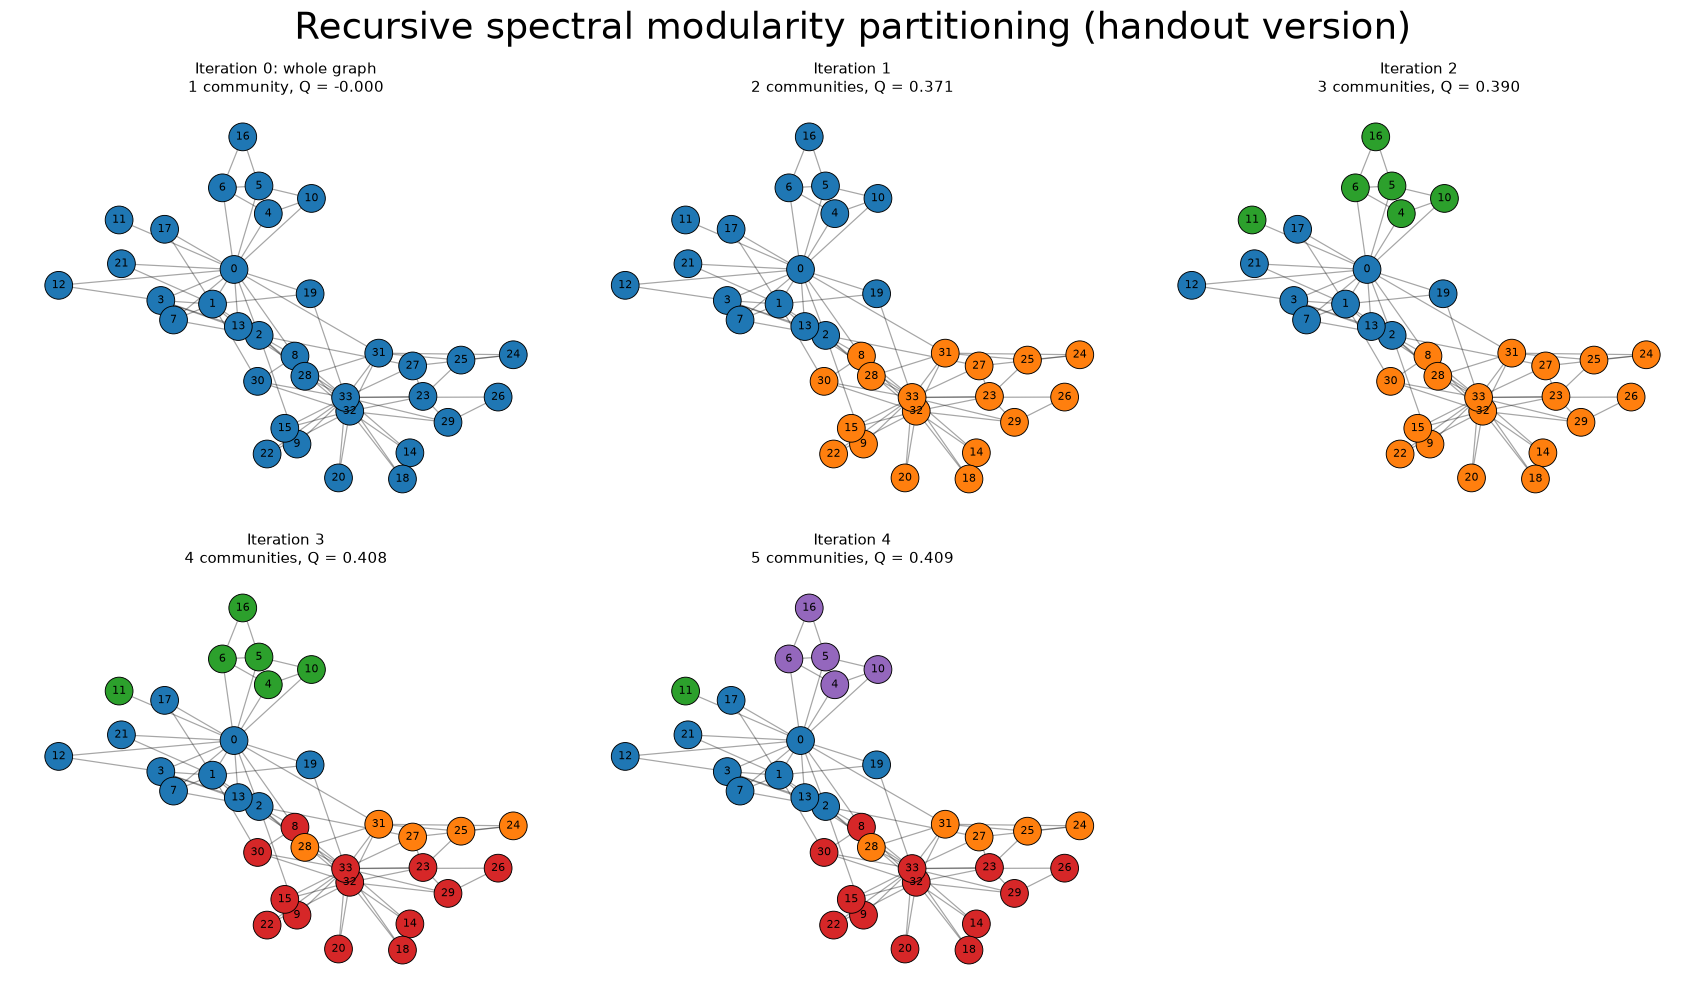

In [48]:
pos = nx.spring_layout(G, seed=42)                  # computed ONCE so every panel uses the same positions
palette = plt.get_cmap("tab10").colors


def draw_partition(ax, communities, title):
    color_of = {}
    for cid, c in communities.items():
        for v in c:
            color_of[v] = palette[cid % len(palette)]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[color_of[v] for v in G.nodes()],
                           node_size=330, edgecolors="black", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def draw_history(hist, qs, suptitle):
    cols = min(3, len(hist))
    rows = int(np.ceil(len(hist) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 4.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for it, (part, q) in enumerate(zip(hist, qs)):
        label = "Iteration 0: whole graph" if it == 0 else f"Iteration {it}"
        draw_partition(axes[it], part, f"{label}\n{len(part)} communit{'y' if len(part)==1 else 'ies'}, Q = {q:.3f}")
    for ax in axes[len(hist):]:
        ax.axis("off")
    fig.suptitle(suptitle, fontsize=24)
    fig.tight_layout()
    plt.show()


draw_history(history, Qs, "Recursive spectral modularity partitioning (handout version)")

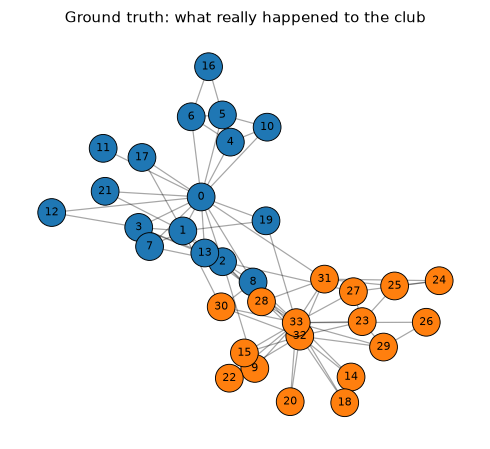

In [40]:
# Real split of the club, for visual comparison with the first iteration
fig, ax = plt.subplots(figsize=(5.5, 4.8))
draw_partition(ax, {0: [i for i in range(n) if truth[i] == 1], 1: [i for i in range(n) if truth[i] == -1]},
               "Ground truth: what really happened to the club")
plt.show()

## 5. Node metrics after each split

**Design choice (important).** The metrics of a node on the *full* graph never change, so plotting them over iterations would give flat lines.
To see how the community structure affects them, at every iteration we compute each metric **inside the node's own community**
(the subgraph induced by that community), exactly as the partition stands after that split. Iteration 0 is the whole graph.

* Degree centrality — fraction of the *other nodes in its community* a node is directly linked to.
* Betweenness centrality — how often the node lies on shortest paths between others in its community.
* Closeness centrality — inverse average distance to the others in its community (NetworkX's default handles
  communities that are not fully connected).
* Clustering coefficient — fraction of a node's neighbours that are also linked to each other (uses only edges inside the community).

In [41]:
metric_funcs = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}


def compute_metrics(hist):
    # returns {metric name: {iteration: {node: value}}}
    out = {name: {} for name in metric_funcs}
    for it, part in enumerate(hist):
        for name, f in metric_funcs.items():
            vals = {}
            for cid, nodes in part.items():
                H = G.subgraph(nodes)                    # graph restricted to this community
                vals.update(f(H))
            out[name][it] = vals
    return out


metrics = compute_metrics(history)

# Full-graph values for reference (iteration 0 is exactly this)
full = {name: f(G) for name, f in metric_funcs.items()}
top = lambda d, r=5: sorted(d, key=d.get, reverse=True)[:r]
for name in metric_funcs:
    print(f"Top 5 on the full graph by {name.lower():24s}:", top(full[name]))

Top 5 on the full graph by degree centrality       : [33, 0, 32, 2, 1]
Top 5 on the full graph by betweenness centrality  : [0, 33, 32, 2, 31]
Top 5 on the full graph by closeness centrality    : [0, 2, 33, 31, 8]
Top 5 on the full graph by clustering coefficient  : [7, 12, 14, 15, 16]


## 6. Evolution of the metrics
One panel per metric; one line per node (34 lines). The five nodes with the highest average value are coloured and labelled,
the other 29 are light grey so the picture stays readable.

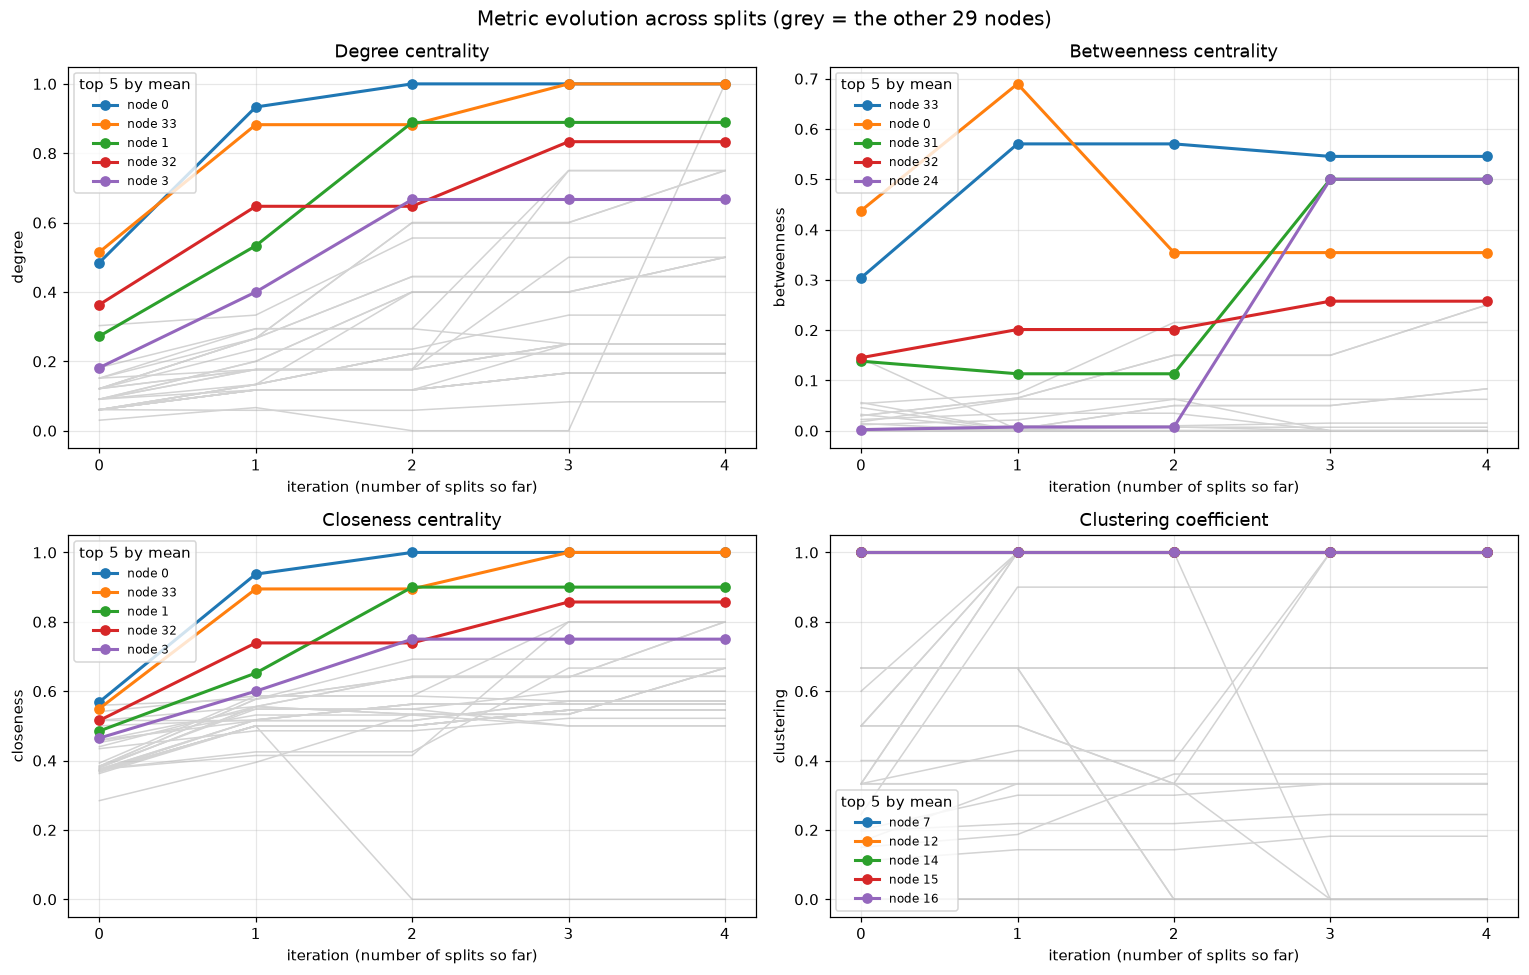

In [ ]:
def plot_metric_evolution(metrics, n_iter, highlight=5):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    its = list(range(n_iter))
    for ax, (name, per_it) in zip(axes.ravel(), metrics.items()):
        series = {v: [per_it[it][v] for it in its] for v in range(n)}
        mean_val = {v: np.mean(series[v]) for v in series}
        best = top(mean_val, highlight)
        for v in range(n):
            if v not in best:
                ax.plot(its, series[v], color="lightgrey", lw=1, zorder=1)
        for j, v in enumerate(best):
            ax.plot(its, series[v], marker="o", lw=2, color=palette[j], label=f"node {v}", zorder=3)
        ax.set_title(name)
        ax.set_xlabel("iteration (number of splits so far)")
        ax.set_xticks(its)
        ax.set_ylabel(name.split()[0].lower())
        ax.legend(title="top 5 by mean", fontsize=8, loc="best")
        ax.grid(alpha=0.3)
    fig.suptitle("Metric evolution across splits (grey = the other 29 nodes)", fontsize=13)
    fig.tight_layout()
    plt.show()


plot_metric_evolution(metrics, len(history))

In [43]:
# Table: the metrics of the five most "central" nodes at every iteration
import pandas as pd

rows = []
for name in metric_funcs:
    for it in range(len(history)):
        vals = metrics[name][it]
        rows.append({"metric": name, "iteration": it, "top 3 nodes": top(vals, 3),
                     "values": [round(vals[v], 3) for v in top(vals, 3)]})
pd.DataFrame(rows).set_index(["metric", "iteration"])

top 3 nodes                 values
metric                 iteration                                     
Degree centrality      0           [33, 0, 32]  [0.515, 0.485, 0.364]
                       1           [0, 33, 32]  [0.933, 0.882, 0.647]
                       2            [0, 1, 33]    [1.0, 0.889, 0.882]
                       3            [0, 33, 1]      [1.0, 1.0, 0.889]
                       4           [0, 11, 33]          [1.0, 1, 1.0]
Betweenness centrality 0           [0, 33, 32]  [0.438, 0.304, 0.145]
                       1           [0, 33, 32]    [0.69, 0.57, 0.201]
                       2            [33, 0, 1]   [0.57, 0.354, 0.215]
                       3          [33, 24, 31]      [0.545, 0.5, 0.5]
                       4          [33, 24, 31]      [0.545, 0.5, 0.5]
Closeness centrality   0            [0, 2, 33]   [0.569, 0.559, 0.55]
                       1           [0, 33, 32]  [0.938, 0.895, 0.739]
                       2            [0, 1, 33]      [1.0, 0.9, 0.895]
                       3            [0, 33, 1]        [1.0, 1.0, 0.9]
                       4            [0, 33, 1]        [1.0, 1.0, 0.9]
Clustering coefficient 0           [7, 12, 14]        [1.0, 1.0, 1.0]
                       1           [7, 12, 13]        [1.0, 1.0, 1.0]
                       2           [7, 12, 13]        [1.0, 1.0, 1.0]
                       3           [7, 12, 13]        [1.0, 1.0, 1.0]
                       4           [7, 12, 13]        [1.0, 1.0, 1.0]

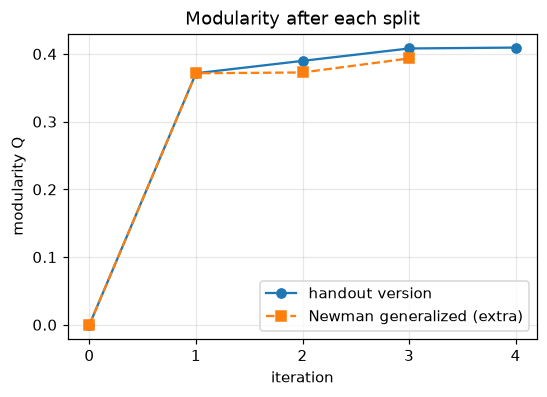

In [44]:
# How does the modularity Q grow with each split?
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(range(len(Qs)), Qs, marker="o", label="handout version")
ax.plot(range(len(Qs_g)), Qs_g, marker="s", ls="--", label="Newman generalized (extra)")
ax.set_xlabel("iteration"); ax.set_ylabel("modularity Q"); ax.grid(alpha=0.3); ax.legend()
ax.set_xticks(range(max(len(Qs), len(Qs_g))))
ax.set_title("Modularity after each split")
plt.show()

## 7. Discussion

**Does the method recover the real split?** The first split (largest eigenvalue 4.98) divides the club 16 vs 18 with modularity Q = 0.371, and it agrees with the real split of the club for 33 of 34 members. The only member put on the "wrong" side is node 8, who has friends on both sides of the dispute (neighbours 0 and 2 on one side, 30, 32 and 33 on the other). Recursive splitting then raised Q to 0.409 with 5 communities and stopped when every community had a leading eigenvalue ≤ 0 or could not be split into two non-empty groups.

**A note on the sub-group matrix.** We followed the handout and used the plain block `B[C, C]`. Newman's (2006) sub-group matrix also subtracts each row sum on the diagonal. Run on the same graph it gives 4 communities with Q = 0.393 and rejects one split that has λ₁ > 0 but would lower Q. So the handout's stopping rule is only an approximation of "no split increases Q"; the plain block can split a little more than is useful (it produced the one-node community {11}).

**Which nodes stay central?** Metrics here are computed inside each node's own community after every split (iteration 0 = whole graph).
* **Nodes 0 and 33**, the two leaders (Mr. Hi and the officer), are the top two nodes for degree, closeness and, until iteration 2, betweenness. Node 0 has the highest degree and closeness (=1.0) from iteration 2 on, and node 33 reaches 1.0 by iteration 3.
* **Node 32** stays in the top 5 for degree, closeness and betweenness throughout (its betweenness rises from 0.145 to 0.26), and **node 1** joins the top 3 for degree and closeness once its community shrinks.
* Clustering is the odd one out. Nodes such as 7, 12 and 13 have clustering 1 almost throughout because their neighbours are all friends with each other, which says "member of a tight clique", not "important".

**How community structure changes the metrics.**
1. *Normalised values jump after the first split.* A community has fewer nodes, so the denominators (n − 1) shrink and the nodes are linked more densely. Node 0's degree centrality goes from 0.485 to 0.933 and its closeness from 0.569 to 0.938 at iteration 1, although nothing about node 0 itself changed.
2. *Betweenness measures brokerage between groups, so it falls when groups are separated.* Node 0's betweenness drops from 0.69 to 0.354 at iteration 2, when the peripheral group {4, 5, 6, 10, 16} (and node 11) is cut away: node 0 no longer lies on their paths to everyone else.
3. *Small communities inflate the numbers.* After iteration 3, nodes 24 and 31 reach betweenness 0.5 only because they sit in the 5-node community {24, 25, 27, 28, 31}, where a handful of shortest paths pass through them. Likewise the one-node community {11} gets degree centrality 1 by the NetworkX convention and closeness 0. These values should not be read as real importance.
4. *Clustering changes when cross-community edges are removed.* A node whose neighbours were split between two communities can see its clustering coefficient jump to 1 (or drop to 0) because only the edges inside its community are counted.

Overall, the two leaders keep the hub positions (high degree and closeness) in every partition, while betweenness and clustering depend much more strongly on how the communities were cut.

## References
Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.

Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.